# 07. Model Evaluation & Ensemble Comparison

This notebook evaluates the performance of individual models (LSTM, Random Forest, XGBoost) and the Ensemble model.

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/gold/drought_forecasting/ensemble_predictions_2022_2025.csv')
df.head()

,year,month,lat_r,lon_r,spei3_lstm,actual_spei_3m,spei3_rf,spei3_xgb,spei3_ensemble,spei3_weighted_ensemble,spei3_weighted_pi95_lower,spei3_weighted_pi95_upper,province,drought_level
0,2022,1,8.6,104.8,0.375956,0.309250,0.102364,0.158982,0.212434,0.216765,-0.248922,0.682452,CàMau,Bình thường
1,2022,1,8.6,104.9,0.371895,0.258137,0.018515,0.030459,0.140289,0.144952,-0.320736,0.610639,CàMau,Bình thường
2,2022,1,8.6,105.0,0.474592,0.401201,0.071956,0.203486,0.250011,0.257119,-0.208568,0.722807,CàMau,Bình thường
3,2022,1,8.7,104.8,0.296108,0.234002,0.088281,0.106324,0.163571,0.166481,-0.299206,0.632168,CàMau,Bình thường
4,2022,1,8.7,104.9,0.282381,0.183545,0.079956,0.081565,0.147967,0.150558,-0.315129,0.616246,CàMau,Bình thường


## 1. Metrics Calculation

In [2]:
def calculate_metrics(y_true, y_pred, name):
    mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    y_t = y_true[mask]
    y_p = y_pred[mask]
    return {
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_t, y_p)),
        'MAE': mean_absolute_error(y_t, y_p),
        'R2': r2_score(y_t, y_p)
    }

metrics = []
for col in ['spei3_lstm', 'spei3_rf', 'spei3_xgb', 'spei3_ensemble']:
    metrics.append(calculate_metrics(df['actual_spei_3m'], df[col], col))

metrics_df = pd.DataFrame(metrics)
metrics_df

,Model,RMSE,MAE,R2
0,spei3_lstm,0.244892,0.187509,0.926995
1,spei3_rf,0.321407,0.248999,0.874248
2,spei3_xgb,0.251017,0.194990,0.923298
3,spei3_ensemble,0.255749,0.199696,0.920379


## 2. Visualization

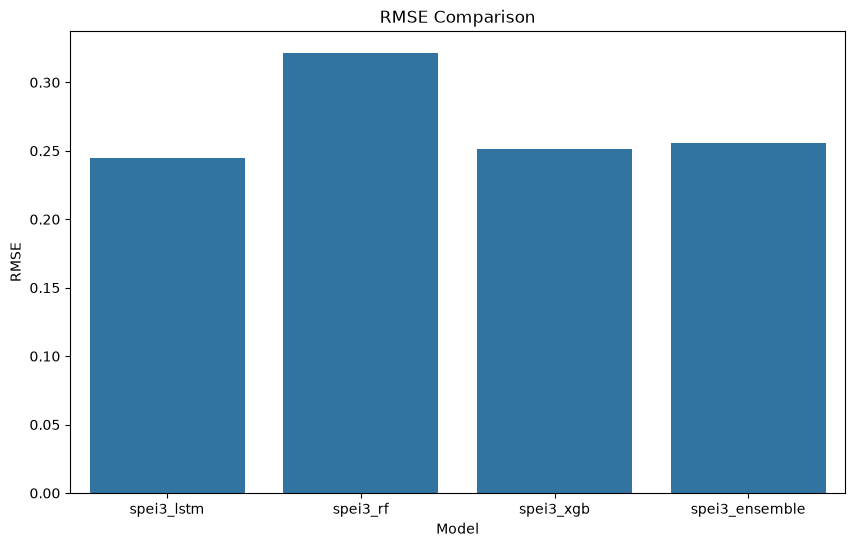

In [3]:
plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_df, x='Model', y='RMSE')
plt.title('RMSE Comparison')
plt.show()

## 3. Regional Forecast Grids (2022–2025)

The panels compare monthly, region-wide mean SPEI-3. RMSE and R² are computed from all grid-cell/month predictions.

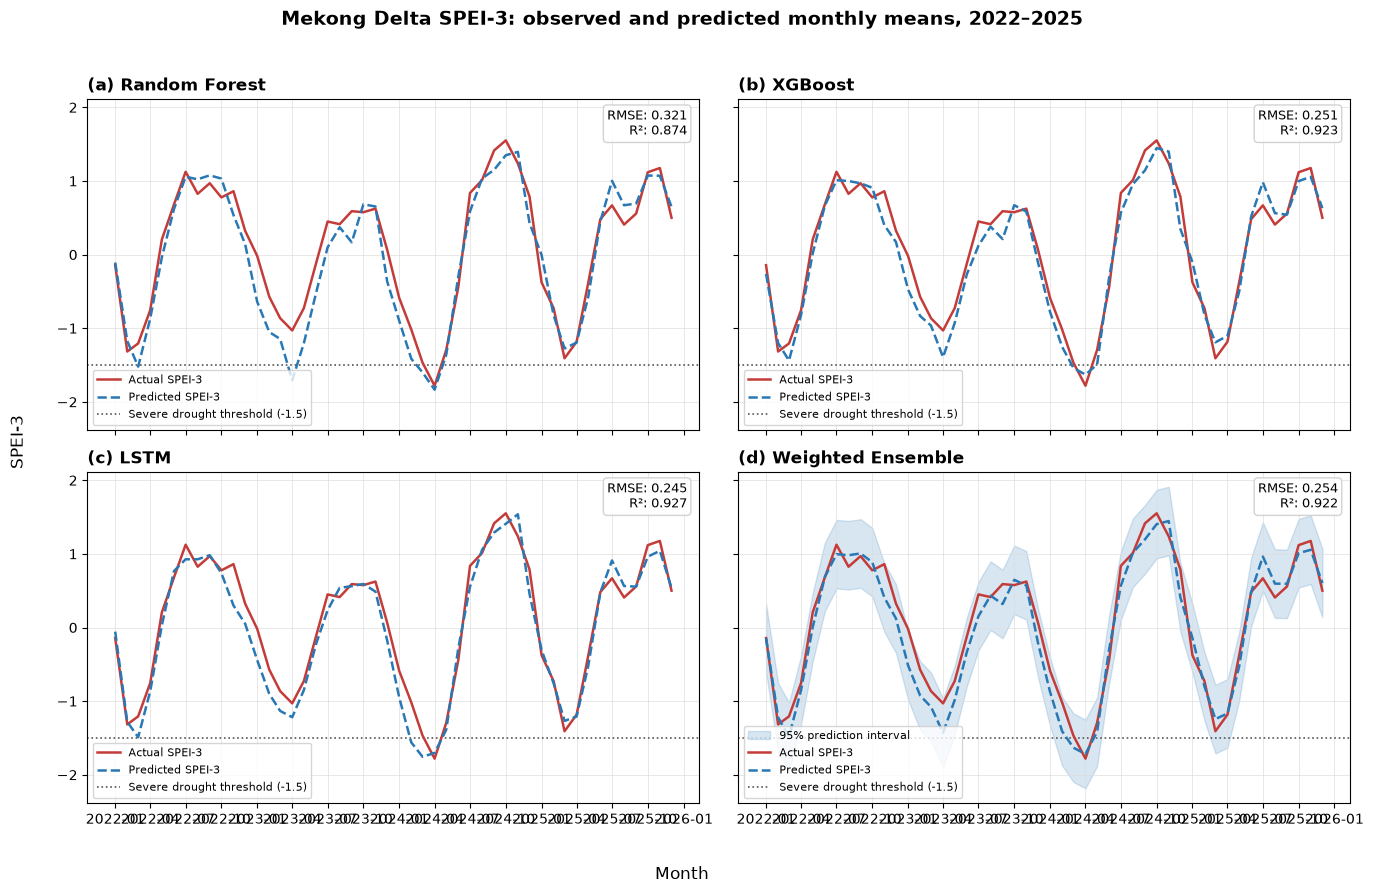

,RMSE,R²
Model,,
Random Forest,0.321,0.874
XGBoost,0.251,0.923
LSTM,0.245,0.927
Weighted Ensemble,0.254,0.922


In [4]:
from pathlib import Path
import matplotlib.dates as mdates

forecast_dir = Path('../data/gold/drought_forecasting')
figure_dir = Path('../reports/figures')
figure_dir.mkdir(parents=True, exist_ok=True)

model_specs = [
    {'name': 'Random Forest', 'file': 'rf_forecast_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'date': 'valid_time'},
    {'name': 'XGBoost', 'file': 'xgboost_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'date': 'valid_time'},
    {'name': 'LSTM', 'file': 'lstm_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'date': 'valid_time'},
    {'name': 'Weighted Ensemble', 'file': 'weighted_ensemble_predictions_2022_2025.csv',
     'prediction': 'weighted_ensemble', 'date': None},
]

regional_model_data = {}
model_metrics = []
for spec in model_specs:
    frame = pd.read_csv(forecast_dir / spec['file'])
    if spec['date'] is None:
        frame['_date'] = pd.to_datetime(dict(year=frame['year'], month=frame['month'], day=1))
    else:
        frame['_date'] = pd.to_datetime(frame[spec['date']]).dt.to_period('M').dt.to_timestamp()
    value_columns = ['actual_spei_3m', spec['prediction']]
    has_interval = spec['name'] == 'Weighted Ensemble'
    if has_interval:
        value_columns += ['weighted_ensemble_pi95_lower', 'weighted_ensemble_pi95_upper']
    valid = frame.dropna(subset=value_columns)
    regional_model_data[spec['name']] = valid.groupby('_date')[value_columns].mean().sort_index()
    model_metrics.append({
        'Model': spec['name'],
        'RMSE': np.sqrt(mean_squared_error(valid['actual_spei_3m'], valid[spec['prediction']])),
        'R²': r2_score(valid['actual_spei_3m'], valid[spec['prediction']]),
    })

panel_specs = [
    ('Random Forest', 'a'), ('XGBoost', 'b'),
    ('LSTM', 'c'), ('Weighted Ensemble', 'd'),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True, sharey=True)
for ax, (model_name, panel) in zip(axes.flat, panel_specs):
    regional = regional_model_data[model_name]
    if model_name == 'Weighted Ensemble':
        ax.fill_between(
            regional.index,
            regional['weighted_ensemble_pi95_lower'],
            regional['weighted_ensemble_pi95_upper'],
            color='#2878B5', alpha=0.18, label='95% prediction interval', zorder=1,
        )
    ax.plot(regional.index, regional['actual_spei_3m'], color='#C43C39',
            linewidth=1.8, label='Actual SPEI-3', zorder=3)
    prediction_column = next(spec['prediction'] for spec in model_specs if spec['name'] == model_name)
    ax.plot(regional.index, regional[prediction_column], color='#2878B5',
            linestyle='--', linewidth=1.8, label='Predicted SPEI-3', zorder=3)
    ax.axhline(-1.5, color='#555555', linestyle=':', linewidth=1.2,
               label='Severe drought threshold (-1.5)', zorder=2)
    metric = next(item for item in model_metrics if item['Model'] == model_name)
    ax.text(0.98, 0.97, f"RMSE: {metric['RMSE']:.3f}\nR²: {metric['R²']:.3f}",
            transform=ax.transAxes, ha='right', va='top', fontsize=9,
            bbox={'boxstyle': 'round,pad=0.3', 'facecolor': 'white', 'alpha': 0.85, 'edgecolor': '#cccccc'})
    ax.set_title(f'({panel}) {model_name}', loc='left', fontweight='bold')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.grid(True, color='#dddddd', linewidth=0.6, alpha=0.8)
    ax.legend(loc='lower left', fontsize=8, frameon=True)

fig.supxlabel('Month')
fig.supylabel('SPEI-3')
fig.suptitle('Mekong Delta SPEI-3: observed and predicted monthly means, 2022–2025',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=(0.02, 0.02, 1, 0.96))
fig.savefig(figure_dir / 'grid_models_comparison_2022_2025.png', dpi=300, bbox_inches='tight')
plt.show()
display(pd.DataFrame(model_metrics).set_index('Model').round(3))

## 4. Province-level SPEI-3 Grids

Monthly means for three coastal and three inland provinces, using the weighted-ensemble forecasts.

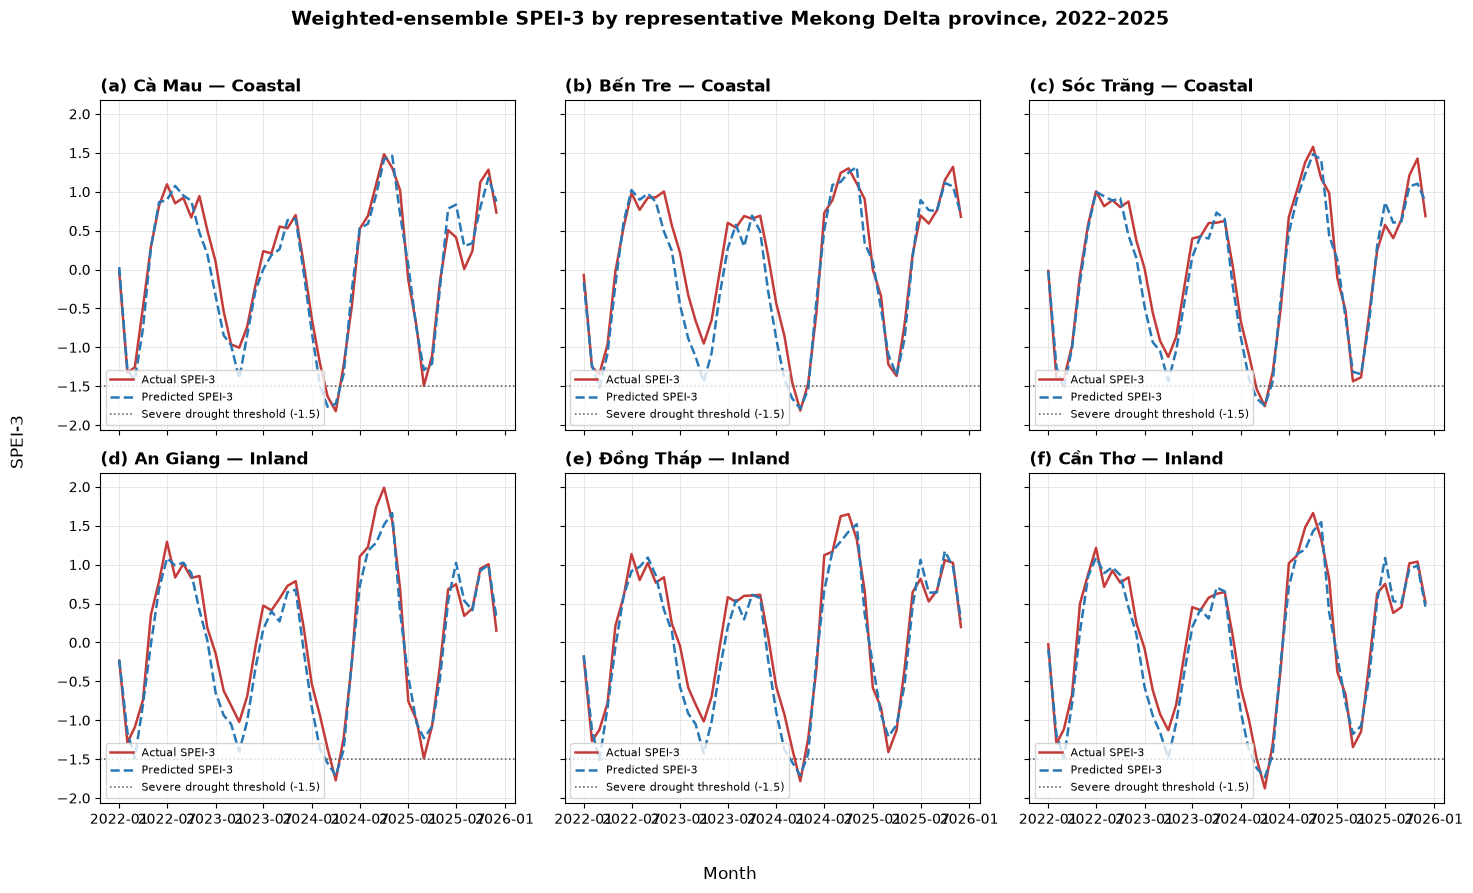

In [5]:
province_predictions = pd.read_csv(forecast_dir / 'weighted_ensemble_predictions_2022_2025.csv')
if 'province' not in province_predictions.columns:
    features = pd.read_parquet('../data/gold/features/gold_drought_features.parquet')
    if 'province' not in features.columns:
        raise ValueError(
            'Forecasts do not include province and gold_drought_features.parquet has no province column to join.'
        )
    feature_lat, feature_lon = ('latitude', 'longitude')
    forecast_lat, forecast_lon = ('lat_r', 'lon_r')
    province_lookup = features[[feature_lat, feature_lon, 'province']].drop_duplicates()
    province_predictions = province_predictions.merge(
        province_lookup,
        left_on=[forecast_lat, forecast_lon],
        right_on=[feature_lat, feature_lon],
        how='left',
        validate='many_to_one',
    )
    if province_predictions['province'].isna().any():
        raise ValueError('Some forecast grid cells could not be matched to a province.')

province_predictions['_date'] = pd.to_datetime(
    dict(year=province_predictions['year'], month=province_predictions['month'], day=1)
)
coastal_provinces = ['Cà Mau', 'Bến Tre', 'Sóc Trăng']
inland_provinces = ['An Giang', 'Đồng Tháp', 'Cần Thơ']
province_order = coastal_provinces + inland_provinces
province_monthly = (
    province_predictions[province_predictions['province'].isin(province_order)]
    .groupby(['province', '_date'])[['actual_spei_3m', 'weighted_ensemble']]
    .mean()
    .reset_index()
)
missing_provinces = set(province_order) - set(province_monthly['province'].unique())
if missing_provinces:
    raise ValueError(f'Missing requested provinces in weighted forecasts: {sorted(missing_provinces)}')

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for index, (ax, province) in enumerate(zip(axes.flat, province_order)):
    monthly = province_monthly[province_monthly['province'] == province].sort_values('_date')
    ax.plot(monthly['_date'], monthly['actual_spei_3m'], color='#C43C39',
            linewidth=1.8, label='Actual SPEI-3')
    ax.plot(monthly['_date'], monthly['weighted_ensemble'], color='#2878B5',
            linestyle='--', linewidth=1.8, label='Predicted SPEI-3')
    ax.axhline(-1.5, color='#555555', linestyle=':', linewidth=1.1,
               label='Severe drought threshold (-1.5)')
    category = 'Coastal' if province in coastal_provinces else 'Inland'
    panel = chr(ord('a') + index)
    ax.set_title(f'({panel}) {province} — {category}', loc='left', fontweight='bold')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.grid(True, color='#dddddd', linewidth=0.6, alpha=0.8)
    ax.legend(loc='lower left', fontsize=8, frameon=True)

fig.supxlabel('Month')
fig.supylabel('SPEI-3')
fig.suptitle('Weighted-ensemble SPEI-3 by representative Mekong Delta province, 2022–2025',
             fontsize=14, fontweight='bold')
fig.tight_layout(rect=(0.02, 0.02, 1, 0.96))
fig.savefig(figure_dir / 'grid_provinces_spei3_2022_2025.png', dpi=300, bbox_inches='tight')
plt.show()

Saved /home/trang/Drought_prediction/reports/figures/violin_models_comparison.png; 1630 grid/model metric values (326 grids × 5 models).


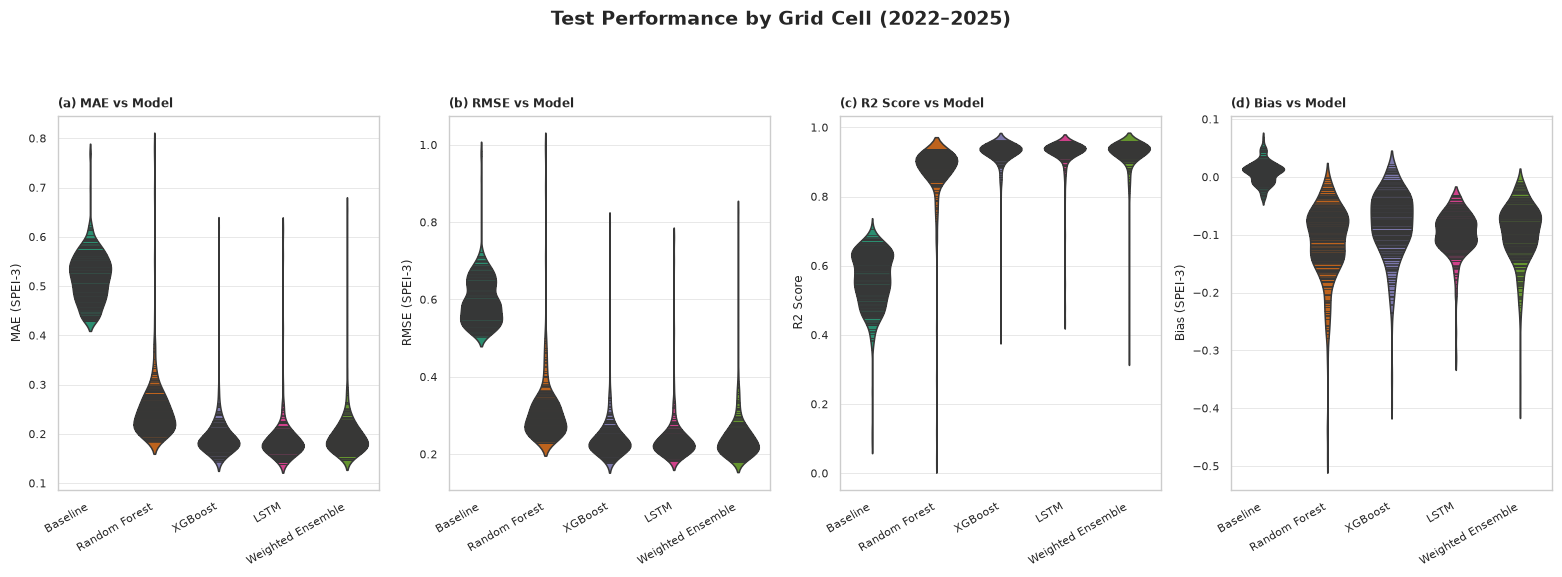

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_root = Path.cwd()
if not (project_root / 'data').is_dir():
    project_root = project_root.parent
forecast_dir = project_root / 'data/gold/drought_forecasting'
figure_path = project_root / 'reports/figures/violin_models_comparison.png'

model_specs = [
    {'name': 'Baseline', 'file': 'baseline_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'latitude': 'lat_r', 'longitude': 'lon_r'},
    {'name': 'Random Forest', 'file': 'rf_forecast_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'latitude': 'latitude', 'longitude': 'longitude'},
    {'name': 'XGBoost', 'file': 'xgboost_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'latitude': 'latitude', 'longitude': 'longitude'},
    {'name': 'LSTM', 'file': 'lstm_predictions_2022_2025.csv',
     'prediction': 'predicted_spei_3m', 'latitude': 'latitude', 'longitude': 'longitude'},
    {'name': 'Weighted Ensemble', 'file': 'weighted_ensemble_predictions_2022_2025.csv',
     'prediction': 'weighted_ensemble', 'latitude': 'lat_r', 'longitude': 'lon_r'},
]
model_order = [spec['name'] for spec in model_specs]
test_start, test_end = pd.Timestamp('2022-01-01'), pd.Timestamp('2025-12-01')
grid_metrics = []
for spec in model_specs:
    frame = pd.read_csv(forecast_dir / spec['file'])
    if 'valid_time' in frame.columns:
        frame['_date'] = pd.to_datetime(frame['valid_time']).dt.to_period('M').dt.to_timestamp()
    elif {'year', 'month'}.issubset(frame.columns):
        frame['_date'] = pd.to_datetime(dict(year=frame['year'], month=frame['month'], day=1))
    else:
        raise KeyError(f"No valid_time or year/month columns in {spec['file']}.")
    frame['_lat_key'] = pd.to_numeric(frame[spec['latitude']], errors='raise').round(1)
    frame['_lon_key'] = pd.to_numeric(frame[spec['longitude']], errors='raise').round(1)
    frame = frame.loc[frame['_date'].between(test_start, test_end)].copy()
    frame['actual_spei_3m'] = pd.to_numeric(frame['actual_spei_3m'], errors='coerce')
    frame['_prediction'] = pd.to_numeric(frame[spec['prediction']], errors='coerce')
    if not np.isfinite(frame[['actual_spei_3m', '_prediction']].to_numpy()).all():
        raise ValueError(f"Non-finite actual/predicted values found in {spec['file']}.")
    grid_keys = ['_lat_key', '_lon_key']
    if frame.duplicated(grid_keys + ['_date']).any():
        raise ValueError(f"Duplicate grid/date rows found in {spec['file']}.")
    grid_count = frame[grid_keys].drop_duplicates().shape[0]
    if grid_count != 326:
        raise ValueError(f"Expected 326 grid cells in {spec['file']}; found {grid_count}.")

    for (latitude, longitude), group in frame.groupby(grid_keys, sort=True):
        if len(group) != 48:
            raise ValueError(f"Expected 48 test months for grid ({latitude}, {longitude}) in {spec['file']}.")
        actual = group['actual_spei_3m'].to_numpy(dtype=float)
        predicted = group['_prediction'].to_numpy(dtype=float)
        grid_metrics.append({
            'Latitude': latitude,
            'Longitude': longitude,
            'Model': spec['name'],
            'MAE': mean_absolute_error(actual, predicted),
            'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'R2 Score': r2_score(actual, predicted),
            'Bias': np.mean(predicted - actual),
        })

metrics_df = pd.DataFrame(grid_metrics)
if len(metrics_df) != 326 * len(model_order):
    raise ValueError(f'Expected {326 * len(model_order)} grid/model metric values; found {len(metrics_df)}.')
if metrics_df.groupby('Model')[['Latitude', 'Longitude']].apply(lambda group: len(group.drop_duplicates())).ne(326).any():
    raise ValueError('Every model must have exactly one metric value for each of the 326 grid cells.')

sns.set_theme(style='whitegrid', context='paper', font_scale=0.9)
palette = dict(zip(model_order, ['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e']))
plot_specs = [
    ('MAE', 'MAE vs Model', 'MAE (SPEI-3)'),
    ('RMSE', 'RMSE vs Model', 'RMSE (SPEI-3)'),
    ('R2 Score', 'R2 Score vs Model', 'R2 Score'),
    ('Bias', 'Bias vs Model', 'Bias (SPEI-3)'),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 6))
for index, (ax, (metric, title, ylabel)) in enumerate(zip(axes, plot_specs)):
    sns.violinplot(
        data=metrics_df,
        x='Model',
        y=metric,
        order=model_order,
        hue='Model',
        hue_order=model_order,
        palette=palette,
        inner='stick',
        cut=1.5,
        bw_adjust=0.8,
        width=0.65,
        dodge=False,
        legend=False,
        linewidth=1.1,
        ax=ax,
    )
    ax.set_title(f'({chr(97 + index)}) {title}', loc='left', fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', labelrotation=30)
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('right')
    ax.grid(axis='y', color='#dddddd', linewidth=0.6, alpha=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)

fig.suptitle('Test Performance by Grid Cell (2022–2025)', fontsize=14, fontweight='bold', y=0.98)
fig.tight_layout(rect=(0.01, 0.03, 0.99, 0.91))
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=300)
print(f'Saved {figure_path}; {len(metrics_df)} grid/model metric values (326 grids × 5 models).')
plt.show()